In [1]:
import pandas as pd 
import seaborn as sns 
import matplotlib.pyplot as plt

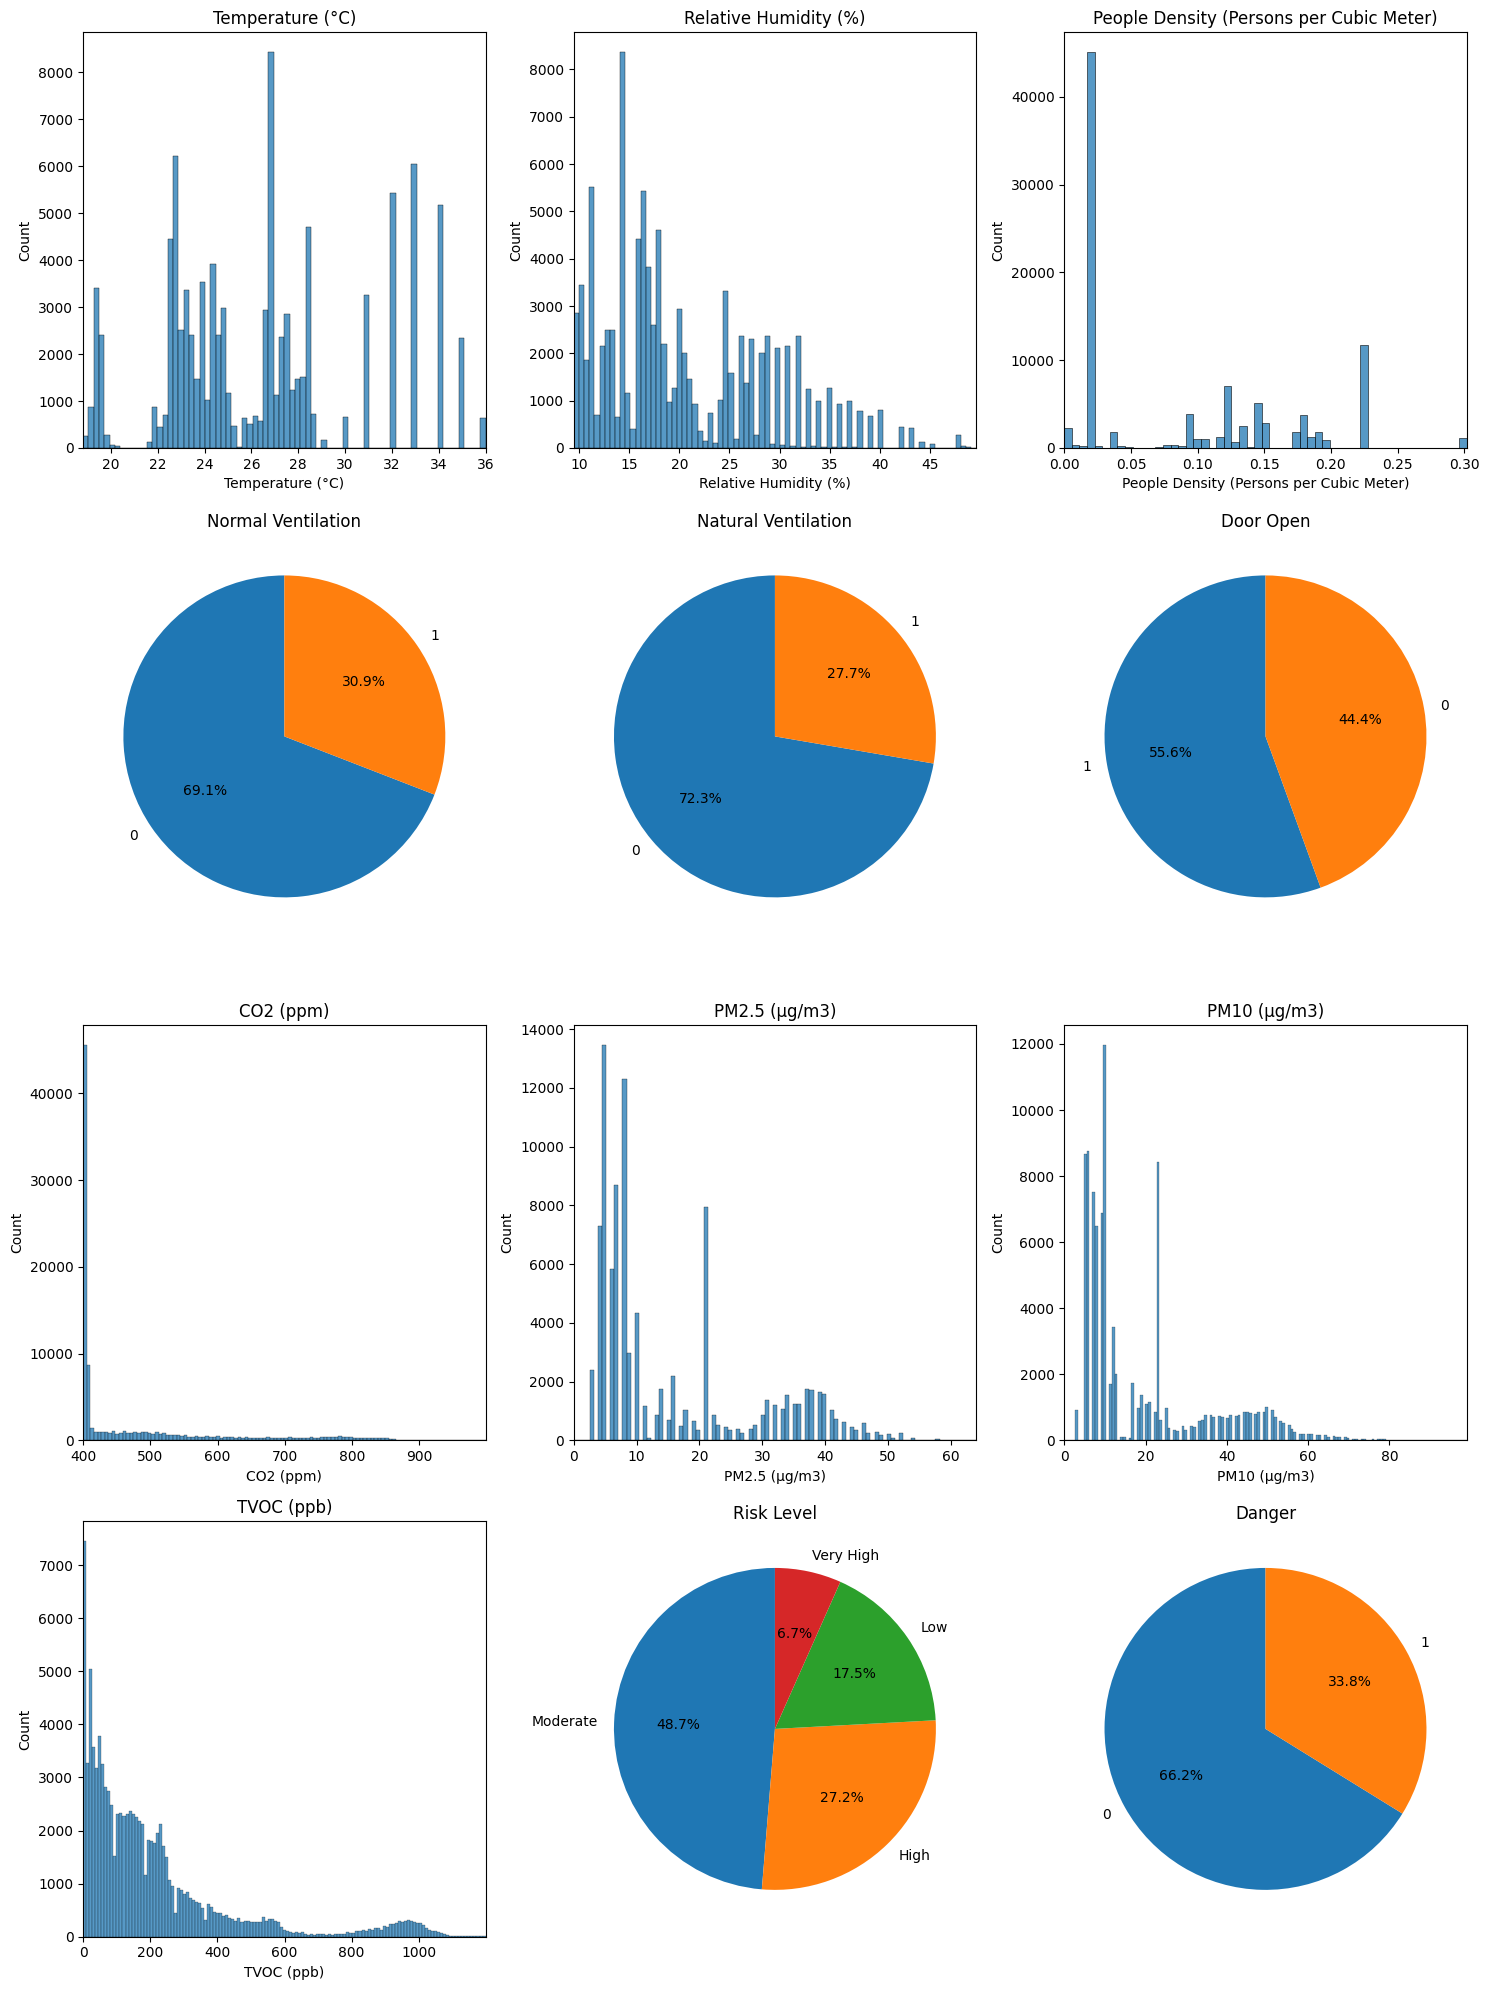

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

df = pd.read_csv('dataset_nuevo_corregido.csv')

df = df[df["Humidity"] < 50]  
df = df[df["Temperature"] < 50]   
df = df[df["PM2.5"] < 100]   
df = df[df["PM10"] < 100]   
df = df[df["CO2"] < 1000]   
df = df[df["TVOC"] < 1200]   

fig, axes = plt.subplots(nrows=4, ncols=3, figsize=(15, 20)) 
plt.subplots_adjust(hspace=0.5, wspace=0.3)

def get_bins(series):
    return np.histogram_bin_edges(series.dropna(), bins='auto')

def set_histogram(ax, series, xlabel):
    bins = get_bins(series)
    sns.histplot(x=series, ax=ax, kde=False, bins=bins)
    ax.set_xlabel(xlabel)
    ax.set_title(xlabel)
    ax.set_xlim(series.min(), series.max())

set_histogram(axes[0, 0], df["Temperature"], "Temperature (°C)")
set_histogram(axes[0, 1], df["Humidity"], "Relative Humidity (%)")
set_histogram(axes[0, 2], df["People density"], "People Density (Persons per Cubic Meter)")

counts = df["Normal ventilation"].value_counts() 
axes[1, 0].pie(counts, labels=counts.index, autopct='%1.1f%%', startangle=90) 
axes[1, 0].set_title("Normal Ventilation")

counts = df["Natural ventilation"].value_counts() 
axes[1, 1].pie(counts, labels=counts.index, autopct='%1.1f%%', startangle=90) 
axes[1, 1].set_title("Natural Ventilation")

counts = df["Door open"].value_counts() 
axes[1, 2].pie(counts, labels=counts.index, autopct='%1.1f%%', startangle=90) 
axes[1, 2].set_title("Door Open")

set_histogram(axes[2, 0], df["CO2"], "CO2 (ppm)")
set_histogram(axes[2, 1], df["PM2.5"], "PM2.5 (µg/m3)")
set_histogram(axes[2, 2], df["PM10"], "PM10 (µg/m3)")

set_histogram(axes[3, 0], df["TVOC"], "TVOC (ppb)")

counts = df["Risk_Label"].value_counts() 
axes[3, 1].pie(counts, labels=counts.index, autopct='%1.1f%%', startangle=90) 
axes[3, 1].set_title("Risk Level")

counts = df["Risk"].value_counts() 
axes[3, 2].pie(counts, labels=counts.index, autopct='%1.1f%%', startangle=90) 
axes[3, 2].set_title("Danger")

plt.tight_layout() 
plt.show()
